<div style="background: linear-gradient(135deg, #102a43, #1f7a8c); padding: 28px; border-radius: 14px; color: white;">
<h1 style="margin: 0;">Linear Regression</h1>
<p style="font-size: 17px; margin-bottom: 0;">A visual introduction to fitting a car-price model with gradient descent.</p>
</div>

## What are we demonstrating?

This notebook introduces the project's standard linear-regression experiment. We use a car's mileage to estimate its price with a straight-line model:

$$\hat{y} = T_0 + T_1x$$

We first fit the line with NumPy as a reference, then train the same two-parameter model with the manual gradient-descent implementation. Finally, we compare both results visually and use the trained model to make predictions.

<div style="background: #e8f1f5; border-left: 6px solid #1f7a8c; padding: 14px 18px; border-radius: 8px;">
<b>Learning objective:</b> understand how the intercept, slope, prediction error, and gradient work together to learn a useful line from data.
</div>

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import StrMethodFormatter

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (11, 5), "axes.titlesize": 15, "axes.labelsize": 11})

DATA_PATH = Path("data.csv")
data = pd.read_csv(DATA_PATH)[["km", "price"]]
data.head()

,km,price
0,240000,3650
1,139800,3800
2,150500,4400
3,185530,4450
4,176000,5250


## 1. Explore the data

Each row contains one car, its mileage in kilometers, and its observed price. The scatter plot lets us inspect the relationship before training a model.

In [2]:
summary = data.describe().T
summary.style.format({"mean": "{:,.1f}", "std": "{:,.1f}", "min": "{:,.1f}", "max": "{:,.1f}"}).background_gradient(cmap="GnBu")

,count,mean,std,min,25%,50%,75%,max
km,24.000000,"101,066.2","52,674.2","22,899.0",65020.500000,83014.500000,140975.000000,"240,000.0"
price,24.000000,"6,331.8","1,319.7","3,650.0",5687.500000,6495.000000,7115.000000,"8,290.0"


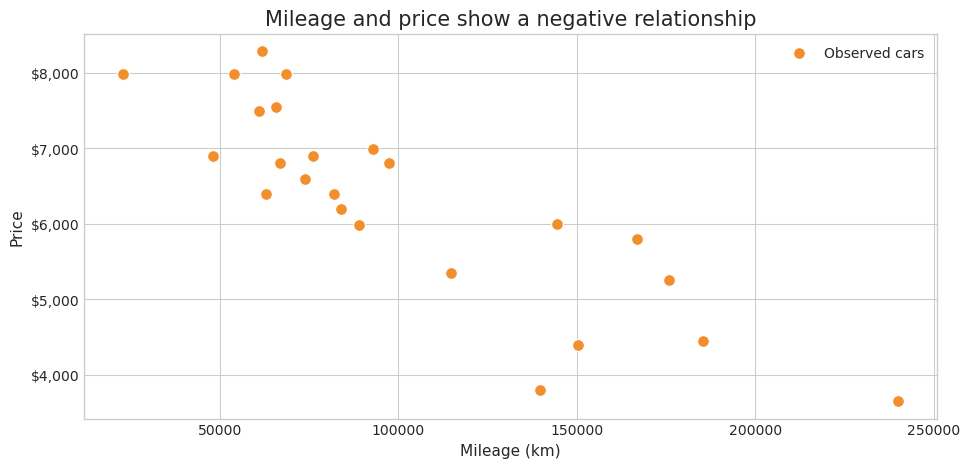

In [3]:
x_values = data["km"].to_numpy(dtype=float)
y_values = data["price"].to_numpy(dtype=float)

fig, ax = plt.subplots(figsize=(11, 5))
ax.scatter(x_values, y_values, s=72, color="#f28e2b", edgecolor="white", linewidth=0.8, label="Observed cars")
ax.set_title("Mileage and price show a negative relationship")
ax.set_xlabel("Mileage (km)")
ax.set_ylabel("Price")
ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax.legend()
plt.show()

## 2. Establish a reference with NumPy

`numpy.polyfit` returns the best-fitting slope and intercept for a first-degree polynomial. These values give us a reference to compare with the custom training algorithm.

Slope (T1):     -0.021449
Intercept (T0): 8,499.60


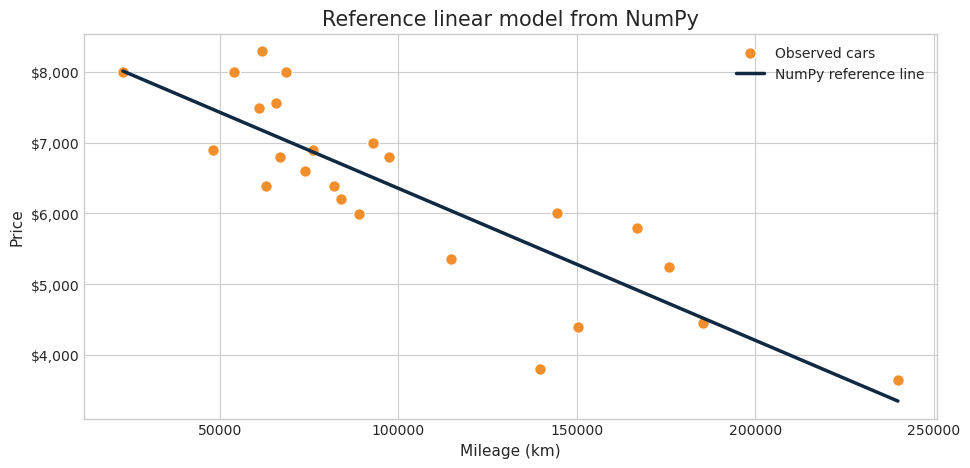

In [4]:
t1, t0 = np.polyfit(x_values, y_values, 1)
polyfit_predictions = t0 + t1 * x_values

print(f"Slope (T1):     {t1:,.6f}")
print(f"Intercept (T0): {t0:,.2f}")

fig, ax = plt.subplots(figsize=(11, 5))
ax.scatter(x_values, y_values, s=72, color="#f28e2b", edgecolor="white", label="Observed cars")
order = np.argsort(x_values)
ax.plot(x_values[order], polyfit_predictions[order], color="#102a43", linewidth=2.5, label="NumPy reference line")
ax.set_title("Reference linear model from NumPy")
ax.set_xlabel("Mileage (km)")
ax.set_ylabel("Price")
ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax.legend()
plt.show()

## 3. Train the model with gradient descent

The project implementation uses a normalized mileage value so that the gradient updates remain numerically stable. Starting from zero parameters, every update moves the model in the direction that reduces mean squared error.

In [5]:
from handMade.train import Model, Trainer

model = Model()
trainer = Trainer(data=data, model=model)

print("Training the manual gradient-descent model...")
trainer.gradient_descent()

trained_intercept = model.params[0]
trained_slope = model.params[1] / trainer.scale
print(f"\nGradient-descent intercept: {trained_intercept:,.2f}")
print(f"Gradient-descent slope:     {trained_slope:,.6f}")

Training the manual gradient-descent model...
Converged after 14000 epochs with loss: 445645.245071
Final parameters: T0 = 8499.599451394815, T1 = -0.021448961868585543

Gradient-descent intercept: 8,499.60
Gradient-descent slope:     -0.021449


In [6]:
gradient_predictions = model.params[0] + model.params[1] / trainer.scale * x_values
comparison = pd.DataFrame({
    "parameter": ["Intercept (T0)", "Slope (T1)"],
    "NumPy reference": [t0, t1],
    "Gradient descent": [trained_intercept, trained_slope],
})
comparison.style.format({"NumPy reference": "{:,.6f}", "Gradient descent": "{:,.6f}"}).background_gradient(cmap="GnBu", axis=1)

,parameter,NumPy reference,Gradient descent
0,Intercept (T0),"8,499.599650","8,499.599451"
1,Slope (T1),-0.021449,-0.021449


## 4. Compare the learned lines

The two lines should describe the same trend: as mileage increases, the estimated price decreases. Small differences are expected because the custom implementation stops when its convergence tolerance is reached.

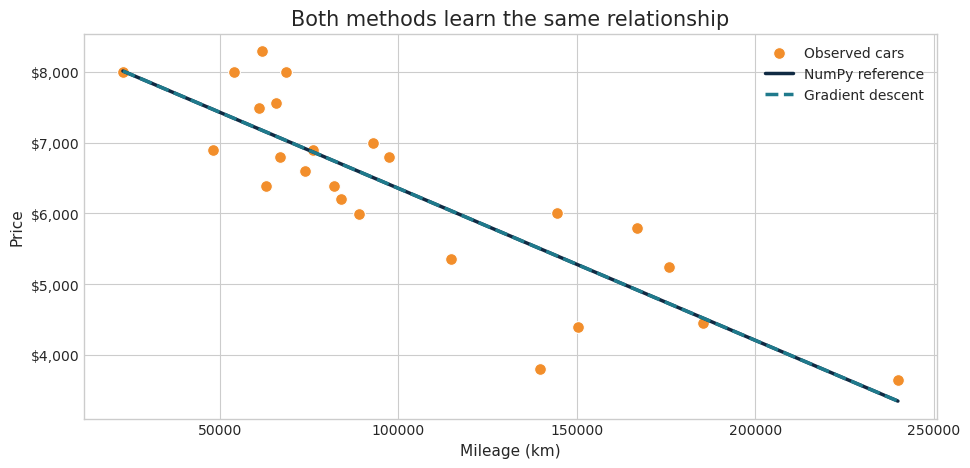

In [7]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.scatter(x_values, y_values, s=72, color="#f28e2b", edgecolor="white", linewidth=0.8, label="Observed cars")
ax.plot(x_values[order], polyfit_predictions[order], color="#102a43", linewidth=2.5, label="NumPy reference")
ax.plot(x_values[order], gradient_predictions[order], color="#1f7a8c", linestyle="--", linewidth=2.5, label="Gradient descent")
ax.set_title("Both methods learn the same relationship")
ax.set_xlabel("Mileage (km)")
ax.set_ylabel("Price")
ax.yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax.legend()
plt.show()

In [8]:
def mse(actual, predicted):
    return np.mean((actual - predicted) ** 2)

metrics = pd.DataFrame({
    "method": ["NumPy reference", "Gradient descent"],
    "MSE": [mse(y_values, polyfit_predictions), mse(y_values, gradient_predictions)],
})
metrics["RMSE"] = np.sqrt(metrics["MSE"])
metrics.style.format({"MSE": "${:,.0f}", "RMSE": "${:,.2f}"}).background_gradient(cmap="YlGn", subset=["RMSE"])

,method,MSE,RMSE
0,NumPy reference,"$445,645",$667.57
1,Gradient descent,"$445,645",$667.57


## 5. Use the trained model for a prediction

Once the parameters have been learned, prediction is just the model equation. The input mileage is scaled in the same way it was during training.

In [9]:
def predict_price(mileage):
    normalized_mileage = mileage / trainer.scale
    return model.params[0] + model.params[1] * normalized_mileage

new_mileage = 90_000
estimated_price = predict_price(new_mileage)

print(f"Mileage: {new_mileage:,.0f} km")
print(f"Estimated price: ${estimated_price:,.2f}")

Mileage: 90,000 km
Estimated price: $6,569.19


<div style="background: #102a43; padding: 20px; border-radius: 12px; color: white;">
<h2 style="margin-top: 0;">Takeaways</h2>
<ul>
<li>Linear regression represents the relationship with an intercept and a slope.</li>
<li>NumPy provides a reference solution for checking the custom implementation.</li>
<li>Gradient descent learns the parameters by repeatedly reducing prediction error.</li>
<li>The learned model can estimate a price for a new mileage value.</li>
</ul>
</div>